In [1]:
import numpy as np
import pandas as pd
from IPython.core.pylabtools import figsize
from plotly.graph_objs import Figure

In [2]:
train_df = pd.read_csv("./dataset/train.csv")
test_df = pd.read_csv("./dataset/test.csv")
sub_df = pd.read_csv("./dataset/sample_submission.csv")

In [3]:
train_df

,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,0,Male,28.0,0,0,Yes,Private,Urban,79.53,31.1,never smoked,0
1,1,Male,33.0,0,0,Yes,Private,Rural,78.44,23.9,formerly smoked,0
2,2,Female,42.0,0,0,Yes,Private,Rural,103.00,40.3,Unknown,0
3,3,Male,56.0,0,0,Yes,Private,Urban,64.87,28.8,never smoked,0
4,4,Female,24.0,0,0,No,Private,Rural,73.36,28.8,never smoked,0
...,...,...,...,...,...,...,...,...,...,...,...,...
15299,15299,Female,22.0,0,0,No,Govt_job,Urban,72.63,19.5,never smoked,0
15300,15300,Female,46.0,1,0,Yes,Private,Urban,101.19,32.1,never smoked,0
15301,15301,Female,75.0,0,0,Yes,Self-employed,Urban,87.69,26.2,never smoked,0
15302,15302,Male,46.0,0,0,Yes,Private,Rural,101.13,22.5,Unknown,0


In [4]:
test_df

,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status
0,15304,Female,57.0,0,0,Yes,Private,Rural,82.54,33.4,Unknown
1,15305,Male,70.0,1,0,Yes,Private,Urban,72.06,28.5,Unknown
2,15306,Female,5.0,0,0,No,children,Urban,103.72,19.5,Unknown
3,15307,Female,56.0,0,0,Yes,Govt_job,Urban,69.24,41.4,smokes
4,15308,Male,32.0,0,0,Yes,Private,Rural,111.15,30.1,smokes
...,...,...,...,...,...,...,...,...,...,...,...
10199,25503,Female,27.0,0,0,No,Private,Urban,75.77,17.6,never smoked
10200,25504,Male,49.0,0,0,Yes,Private,Urban,102.91,26.7,Unknown
10201,25505,Female,3.0,0,0,No,children,Rural,104.04,18.3,Unknown
10202,25506,Male,31.0,0,0,Yes,Private,Urban,82.41,28.7,never smoked


In [5]:
train_df['stroke'].unique()

array([0, 1])

In [6]:
train_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15304 entries, 0 to 15303
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 15304 non-null  int64  
 1   gender             15304 non-null  object 
 2   age                15304 non-null  float64
 3   hypertension       15304 non-null  int64  
 4   heart_disease      15304 non-null  int64  
 5   ever_married       15304 non-null  object 
 6   work_type          15304 non-null  object 
 7   Residence_type     15304 non-null  object 
 8   avg_glucose_level  15304 non-null  float64
 9   bmi                15304 non-null  float64
 10  smoking_status     15304 non-null  object 
 11  stroke             15304 non-null  int64  
dtypes: float64(3), int64(4), object(5)
memory usage: 1.4+ MB


In [7]:
train_df.describe()

,id,age,hypertension,heart_disease,avg_glucose_level,bmi,stroke
count,15304.000000,15304.000000,15304.000000,15304.000000,15304.000000,15304.000000,15304.000000
mean,7651.500000,41.417708,0.049726,0.023327,89.039853,28.112721,0.041296
std,4418.028595,21.444673,0.217384,0.150946,25.476102,6.722315,0.198981
min,0.000000,0.080000,0.000000,0.000000,55.220000,10.300000,0.000000
25%,3825.750000,26.000000,0.000000,0.000000,74.900000,23.500000,0.000000
50%,7651.500000,43.000000,0.000000,0.000000,85.120000,27.600000,0.000000
75%,11477.250000,57.000000,0.000000,0.000000,96.980000,32.000000,0.000000
max,15303.000000,82.000000,1.000000,1.000000,267.600000,80.100000,1.000000


In [8]:
train_df.describe().T

,count,mean,std,min,25%,50%,75%,max
id,15304.0,7651.500000,4418.028595,0.00,3825.75,7651.50,11477.25,15303.0
age,15304.0,41.417708,21.444673,0.08,26.00,43.00,57.00,82.0
hypertension,15304.0,0.049726,0.217384,0.00,0.00,0.00,0.00,1.0
heart_disease,15304.0,0.023327,0.150946,0.00,0.00,0.00,0.00,1.0
avg_glucose_level,15304.0,89.039853,25.476102,55.22,74.90,85.12,96.98,267.6
bmi,15304.0,28.112721,6.722315,10.30,23.50,27.60,32.00,80.1
stroke,15304.0,0.041296,0.198981,0.00,0.00,0.00,0.00,1.0


In [9]:
train_df.nunique()

id                   15304
gender                   3
age                    106
hypertension             2
heart_disease            2
ever_married             2
work_type                5
Residence_type           2
avg_glucose_level     3740
bmi                    407
smoking_status           4
stroke                   2
dtype: int64

In [10]:
train_df.duplicated().sum()

np.int64(0)

In [11]:
train_df.isnull()

,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,False,False,False,False,False,False,False,False,False,False,False,False
1,False,False,False,False,False,False,False,False,False,False,False,False
2,False,False,False,False,False,False,False,False,False,False,False,False
3,False,False,False,False,False,False,False,False,False,False,False,False
4,False,False,False,False,False,False,False,False,False,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...
15299,False,False,False,False,False,False,False,False,False,False,False,False
15300,False,False,False,False,False,False,False,False,False,False,False,False
15301,False,False,False,False,False,False,False,False,False,False,False,False
15302,False,False,False,False,False,False,False,False,False,False,False,False


### Data Cleaning

In [12]:
len(sorted(train_df['age'].unique().tolist()))

106

In [13]:
train_df['age'] = np.ceil(train_df['age'])
test_df['age'] = np.ceil(test_df['age'])

In [14]:
train_df['gender'].value_counts()

gender
Female    9446
Male      5857
Other        1
Name: count, dtype: int64

In [15]:
train_df = train_df[train_df['gender']!='Other']
train_df['gender'].value_counts()

gender
Female    9446
Male      5857
Name: count, dtype: int64

In [16]:
test_df = test_df[test_df['gender']!='Other']

In [17]:
test_df['gender'].value_counts()

gender
Female    6338
Male      3865
Name: count, dtype: int64

### EDA (Exploratory Data Analytics)

In [18]:
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go
import plotly.subplots as sp
sns.set_style("whitegrid")

In [19]:
plot_color = ['#D4A017', '#3F37C9']
sns.set_palette(['#D4A017', '#3F37C9'])

In [20]:
no_stroke_data = train_df[train_df['stroke']==0]
stroke_data = train_df[train_df['stroke']==1]

In [21]:
stroke_count = train_df['stroke'].value_counts()
print(stroke_count)

stroke
0    14671
1      632
Name: count, dtype: int64


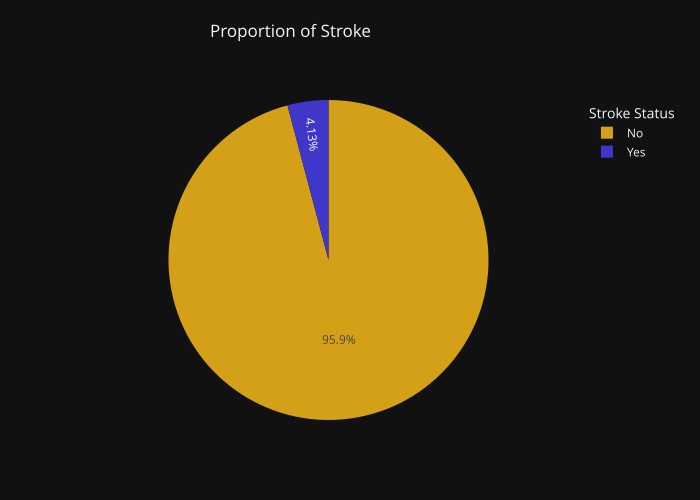

In [22]:
fig = px.pie(
    values=stroke_count.values,
    names=stroke_count.index.map({0: 'No', 1: 'Yes'}),
    title='Proportion of Stroke',
    color_discrete_sequence=plot_color
)
fig.update_layout(legend_title_text='Stroke Status', title_x=0.3, title_y=0.95)
fig.show('svg')

### Bivariate Analysis

In [23]:
def custom_histogram(columns: str, titles:list) -> go.Figure:
    fig = sp.make_subplots(rows=1, cols=2, subplot_titles=['No Stroke', "Yes Stroke"])
    histogram_no_stroke = px.histogram(no_stroke_data, x=columns, color_discrete_sequence=['#D4A017'])
    histogram_stroke = px.histogram(stroke_data, x=columns, color_discrete_sequence=['#3F37C9'])
    fig.add_trace(histogram_no_stroke['data'][0], row=1, col=1)
    fig.add_trace(histogram_stroke['data'][0], row=1, col=2)
    fig.update_layout(title=titles[0], title_x=0.5, showlegend=False)
    fig.update_xaxes(title_text=titles[1])
    fig.update_yaxes(title_text='Count')
    return fig

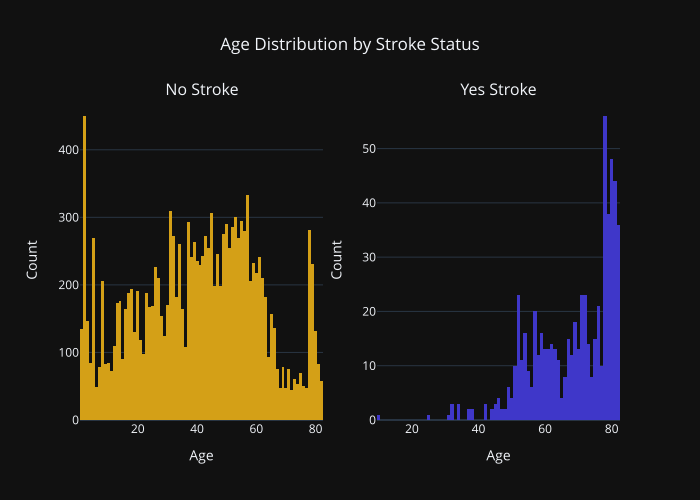

In [24]:
custom_histogram('age', ['Age Distribution by Stroke Status', 'Age']).show('svg')

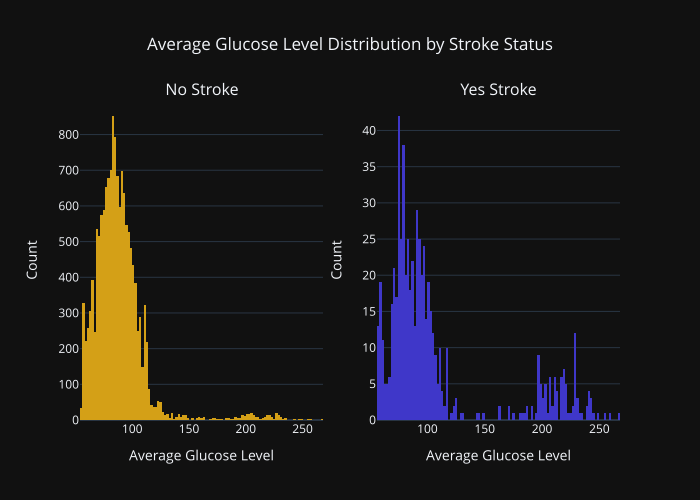

In [25]:
custom_histogram('avg_glucose_level', ['Average Glucose Level Distribution by Stroke Status', 'Average Glucose Level']).show('svg')

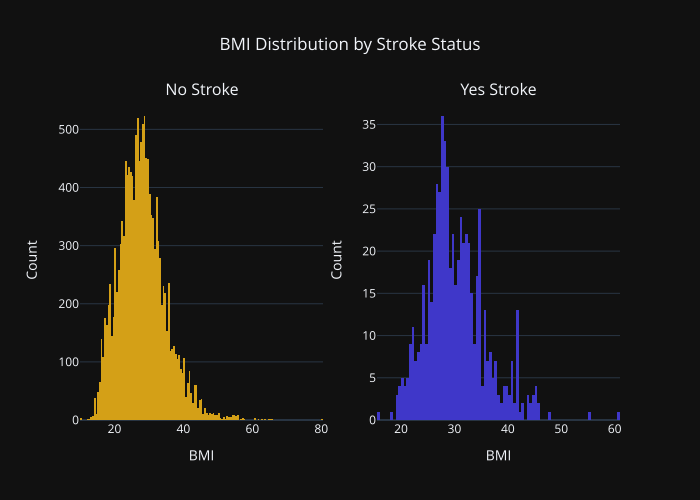

In [26]:
custom_histogram('bmi', ['BMI Distribution by Stroke Status', 'BMI']).show('svg')

In [27]:
stroke_data['bmi'].mean()

np.float64(30.230696202531643)

In [28]:
no_stroke_data['bmi'].mean()

np.float64(28.02217163110899)

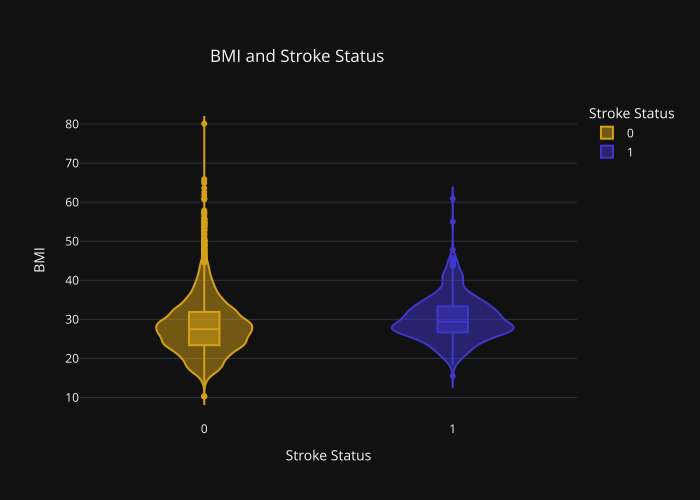

In [29]:
fig = px.violin(
    train_df,
    y='bmi',
    x='stroke',
    color='stroke',
    box=True,
    width=700,
    height=500,
    color_discrete_sequence=plot_color,
    title='BMI and Stroke Status',
    labels={'stroke': 'Stroke Status', 'bmi': 'BMI'}
)
fig.update_layout(title_x=0.3, title_y=0.9)
fig.show('svg')

In [30]:
train_df.columns

Index(['id', 'gender', 'age', 'hypertension', 'heart_disease', 'ever_married',
       'work_type', 'Residence_type', 'avg_glucose_level', 'bmi',
       'smoking_status', 'stroke'],
      dtype='object')

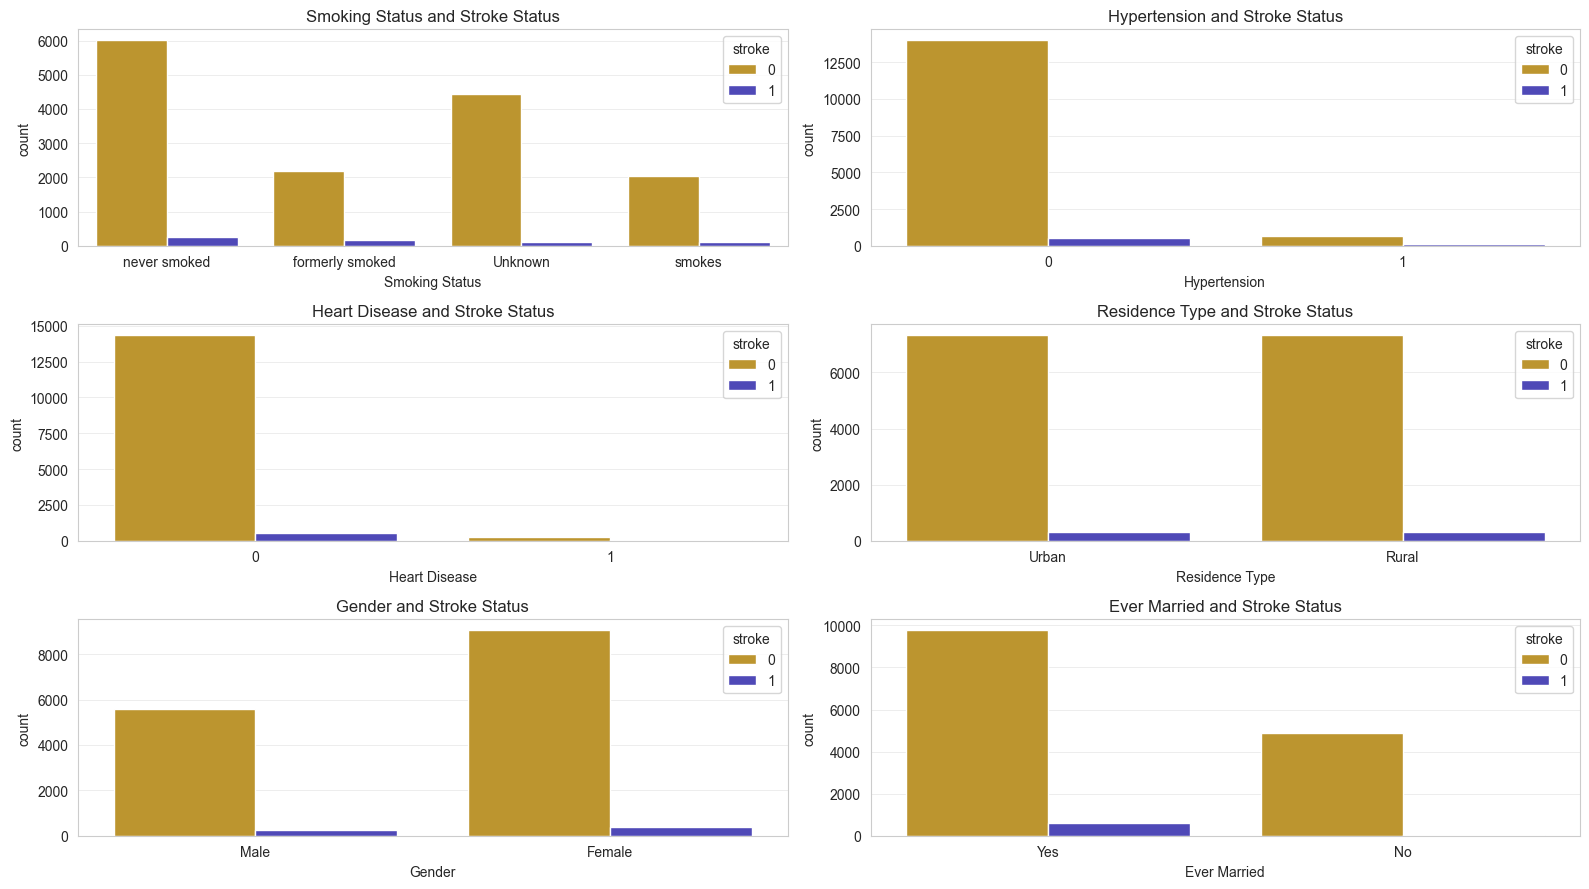

In [31]:
x_values = ['smoking_status', 'hypertension', 'heart_disease', 'Residence_type', 'gender', 'ever_married']
fig, axis = plt.subplots(nrows=3, ncols=2, figsize=(16, 9))

for ax, x_value in zip(axis.flat, x_values):
    sns.countplot(data=train_df, x=x_value, hue='stroke', ax=ax)
    ax.set_title(f"{x_value.replace('_', ' ').title()} and Stroke Status")
    ax.set_xlabel(x_value.replace('_', ' ').title())

plt.tight_layout()
plt.show()

### Data preparation and preprocessing

In [32]:
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn import set_config
set_config(display = 'diagram')

In [33]:
train_df.columns

Index(['id', 'gender', 'age', 'hypertension', 'heart_disease', 'ever_married',
       'work_type', 'Residence_type', 'avg_glucose_level', 'bmi',
       'smoking_status', 'stroke'],
      dtype='object')

In [34]:
input_cols = list(train_df.columns)[1:-1]
input_cols

['gender',
 'age',
 'hypertension',
 'heart_disease',
 'ever_married',
 'work_type',
 'Residence_type',
 'avg_glucose_level',
 'bmi',
 'smoking_status']

In [35]:
target_col = 'stroke'

In [36]:
train_inputs = train_df[input_cols].copy()
train_target = train_df[target_col].copy()

test_input = test_df[input_cols].copy()

In [37]:
numerical_cols = train_inputs.select_dtypes(include=np.number).columns.tolist()
numerical_cols

['age', 'hypertension', 'heart_disease', 'avg_glucose_level', 'bmi']

In [38]:
categorical_cols = train_inputs.select_dtypes(include='object').columns.tolist()
categorical_cols

['gender', 'ever_married', 'work_type', 'Residence_type', 'smoking_status']

In [39]:
train_df.nunique()

id                   15303
gender                   2
age                     82
hypertension             2
heart_disease            2
ever_married             2
work_type                5
Residence_type           2
avg_glucose_level     3740
bmi                    407
smoking_status           4
stroke                   2
dtype: int64

In [40]:
train_df['gender'].nunique()

2

In [41]:
categorical_cols.remove('smoking_status')

In [42]:
train_df['smoking_status'].unique()

array(['never smoked', 'formerly smoked', 'Unknown', 'smokes'],
      dtype=object)

In [43]:
ordinal_encoding = OrdinalEncoder(categories=[['Unknown', 'never smoked', 'formerly smoked', 'smokes']])

In [44]:
onehot_encoder = OneHotEncoder(handle_unknown='ignore', sparse_output=False)

In [45]:
preprocessor = ColumnTransformer([
    ('Ordinal_Encode', ordinal_encoding, ['smoking_status']),
    ('OneHot_Encode', onehot_encoder, categorical_cols),
])

In [46]:
preprocessor.fit(train_inputs)

ColumnTransformer(transformers=[('Ordinal_Encode',
                                 OrdinalEncoder(categories=[['Unknown',
                                                             'never smoked',
                                                             'formerly smoked',
                                                             'smokes']]),
                                 ['smoking_status']),
                                ('OneHot_Encode',
                                 OneHotEncoder(handle_unknown='ignore',
                                               sparse_output=False),
                                 ['gender', 'ever_married', 'work_type',
                                  'Residence_type'])])

In [47]:
encoded_cols = list(preprocessor.get_feature_names_out())
encoded_cols

['Ordinal_Encode__smoking_status',
 'OneHot_Encode__gender_Female',
 'OneHot_Encode__gender_Male',
 'OneHot_Encode__ever_married_No',
 'OneHot_Encode__ever_married_Yes',
 'OneHot_Encode__work_type_Govt_job',
 'OneHot_Encode__work_type_Never_worked',
 'OneHot_Encode__work_type_Private',
 'OneHot_Encode__work_type_Self-employed',
 'OneHot_Encode__work_type_children',
 'OneHot_Encode__Residence_type_Rural',
 'OneHot_Encode__Residence_type_Urban']

In [48]:
train_inputs[encoded_cols] = preprocessor.transform(train_inputs)
test_input[encoded_cols] = preprocessor.transform(test_input)

In [49]:
X_train = train_inputs[numerical_cols + encoded_cols]
y_train = train_df[target_col]

X_test = test_input[numerical_cols + encoded_cols]

In [50]:
X_train.head()

,age,hypertension,heart_disease,avg_glucose_level,bmi,Ordinal_Encode__smoking_status,OneHot_Encode__gender_Female,OneHot_Encode__gender_Male,OneHot_Encode__ever_married_No,OneHot_Encode__ever_married_Yes,OneHot_Encode__work_type_Govt_job,OneHot_Encode__work_type_Never_worked,OneHot_Encode__work_type_Private,OneHot_Encode__work_type_Self-employed,OneHot_Encode__work_type_children,OneHot_Encode__Residence_type_Rural,OneHot_Encode__Residence_type_Urban
0,28.0,0,0,79.53,31.1,1.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0
1,33.0,0,0,78.44,23.9,2.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0
2,42.0,0,0,103.00,40.3,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0
3,56.0,0,0,64.87,28.8,1.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0
4,24.0,0,0,73.36,28.8,1.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0


In [51]:
X_train.shape[1] == X_test.shape[1]

True

In [52]:
from sklearn.model_selection import train_test_split
X_tr, X_val, y_tr, y_val = train_test_split(
    X_train, y_train, test_size=0.2, random_state=42, stratify=y_train
)

In [53]:
X_train.shape

(15303, 17)

In [54]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from lightgbm import LGBMClassifier
from xgboost import XGBClassifier
from imblearn.over_sampling import SMOTE
from sklearn.metrics import confusion_matrix, accuracy_score, precision_score, recall_score, f1_score

In [55]:
models = [
    (LogisticRegression(max_iter=1000), 'Logistic Regression'),
    (RandomForestClassifier(random_state=42), 'Random Forest'),
    (XGBClassifier(random_state=42), 'XGBoost'),
    (LGBMClassifier(random_state=42, verbose=-1), 'LightGBM'),
]

In [56]:
def evaluate_model(model, X, y):
    y_pred = model.predict(X)
    cm = confusion_matrix(y, y_pred)
    accuracy = accuracy_score(y, y_pred)
    precision = precision_score(y, y_pred, zero_division=0)
    recall = recall_score(y, y_pred)
    f1 = f1_score(y, y_pred, zero_division=0)
    return cm, accuracy, precision, recall, f1

In [57]:
confusion_mats = {}
def metric_df(model, model_name, X_test, y_test):
    cm, accuracy, precision, recall, f1 = evaluate_model(model, X_test, y_test)
    confusion_mats[model_name] = cm
    return pd.DataFrame({
        'Model': [model_name],
        'Accuracy': [accuracy],
        'Precision': [precision],
        'Recall': [recall],
        'F1': [f1],
    })

In [58]:
import warnings
warnings.filterwarnings('ignore')

results = []
for model, model_name in models:
    model.fit(X_tr, y_tr)
    results.append(metric_df(model, model_name, X_val, y_val))

results_df = pd.concat(results, ignore_index=True)
results_df.sort_values('F1', ascending=False)

,Model,Accuracy,Precision,Recall,F1
1,Random Forest,0.958837,0.500000,0.071429,0.125000
2,XGBoost,0.955570,0.321429,0.071429,0.116883
3,LightGBM,0.956223,0.333333,0.063492,0.106667
0,Logistic Regression,0.959164,0.600000,0.023810,0.045802


In [59]:
oversample = SMOTE(random_state=42)
X_tr_sm, y_tr_sm = oversample.fit_resample(X_tr, y_tr)

In [60]:
X_tr_sm.shape, y_tr_sm.value_counts()

((23472, 17),
 stroke
 0    11736
 1    11736
 Name: count, dtype: int64)

In [61]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

lr_with_smote = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
lr_with_smote.fit(X_tr_sm, y_tr_sm)
results.append(metric_df(lr_with_smote, 'Logistic Regression + SMOTE', X_val, y_val))

In [62]:
results_df = pd.concat(results, ignore_index=True).sort_values('F1', ascending=False)
results_df

,Model,Accuracy,Precision,Recall,F1
4,Logistic Regression + SMOTE,0.782424,0.132153,0.769841,0.225581
1,Random Forest,0.958837,0.500000,0.071429,0.125000
2,XGBoost,0.955570,0.321429,0.071429,0.116883
3,LightGBM,0.956223,0.333333,0.063492,0.106667
0,Logistic Regression,0.959164,0.600000,0.023810,0.045802


In [63]:
for model_name, confusion_mat in confusion_mats.items():
    print(f'Confusion Matrix for {model_name}')
    print(confusion_mat)
    print()

Confusion Matrix for Logistic Regression
[[2933    2]
 [ 123    3]]

Confusion Matrix for Random Forest
[[2926    9]
 [ 117    9]]

Confusion Matrix for XGBoost
[[2916   19]
 [ 117    9]]

Confusion Matrix for LightGBM
[[2919   16]
 [ 118    8]]

Confusion Matrix for Logistic Regression + SMOTE
[[2298  637]
 [  29   97]]



### Voting Classifier -> Hard and Soft

In [64]:
from sklearn.ensemble import VotingClassifier

estimators = [
    ('lr', make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))),
    ('rf', RandomForestClassifier(random_state=42)),
    ('lgbm', LGBMClassifier(random_state=42, verbose=-1)),
    ('xgb', XGBClassifier(random_state=42)),
]

In [65]:
vc_hard = VotingClassifier(estimators=estimators, voting='hard')
vc_hard.fit(X_tr, y_tr)
results.append(metric_df(vc_hard, 'Voting (Hard)', X_val, y_val))

In [66]:
vc_soft = VotingClassifier(estimators=estimators, voting='soft')
vc_soft.fit(X_tr, y_tr)
results.append(metric_df(vc_soft, 'Voting (Soft)', X_val, y_val))

In [67]:
results_df = pd.concat(results, ignore_index=True).sort_values('Recall', ascending=False)
results_df

,Model,Accuracy,Precision,Recall,F1
4,Logistic Regression + SMOTE,0.782424,0.132153,0.769841,0.225581
1,Random Forest,0.958837,0.500000,0.071429,0.125000
2,XGBoost,0.955570,0.321429,0.071429,0.116883
3,LightGBM,0.956223,0.333333,0.063492,0.106667
6,Voting (Soft),0.958184,0.428571,0.047619,0.085714
0,Logistic Regression,0.959164,0.600000,0.023810,0.045802
5,Voting (Hard),0.959164,0.600000,0.023810,0.045802


In [68]:
models_to_plot = [
    'Logistic Regression',
    'Random Forest',
    'XGBoost',
    'Logistic Regression + SMOTE',
]

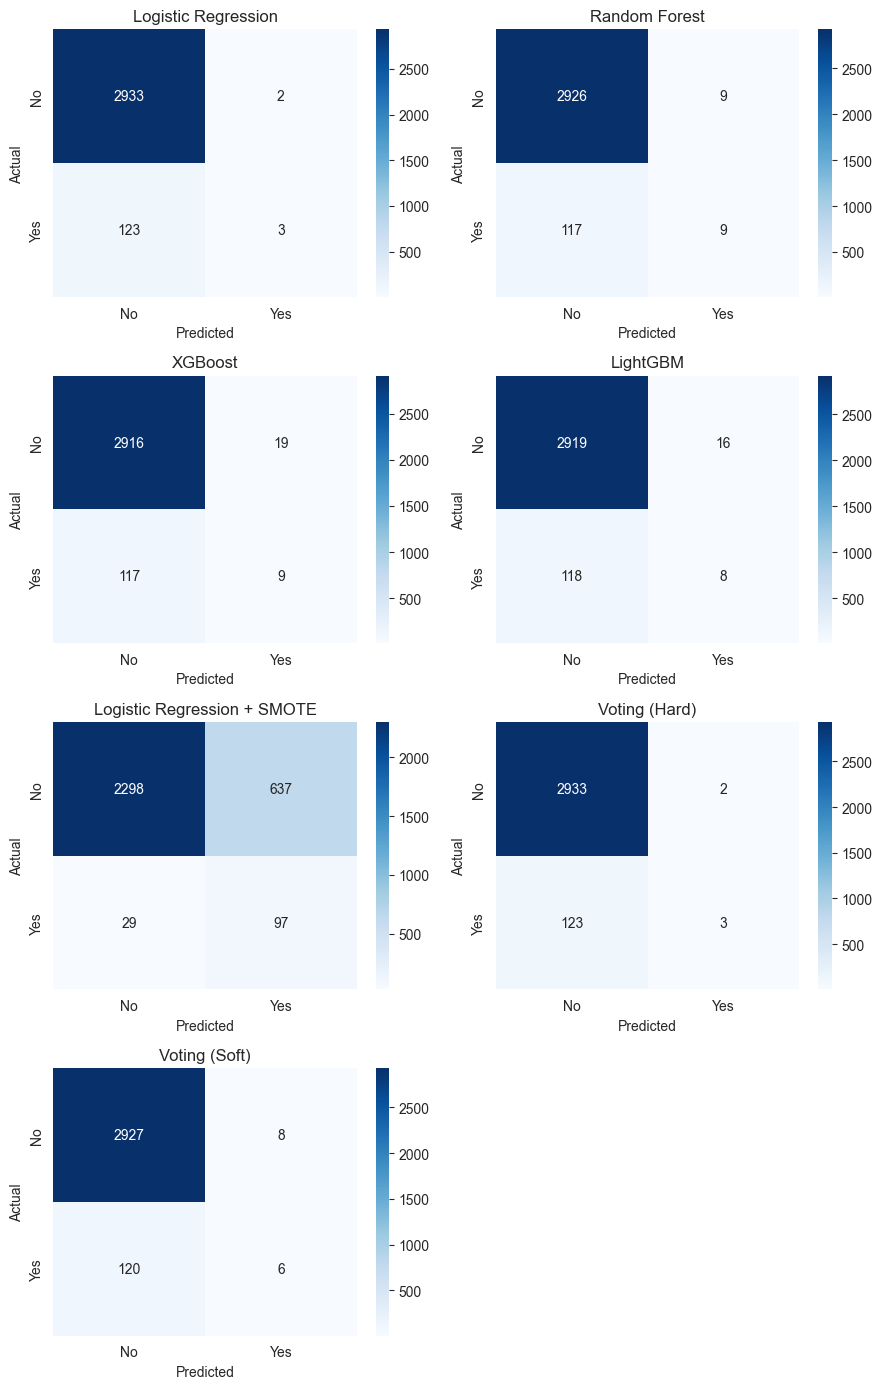

In [69]:
n = len(confusion_mats)
ncols = 2
nrows = -(-n // ncols)  # ceiling division
fig, axes = plt.subplots(nrows=nrows, ncols=ncols, figsize=(9, 3.5 * nrows))
for ax, model_name in zip(axes.ravel(), confusion_mats):
    sns.heatmap(
        confusion_mats[model_name], annot=True, fmt='d', cmap='Blues', ax=ax,
        xticklabels=['No', 'Yes'], yticklabels=['No', 'Yes']
    )
    ax.set_title(model_name)
    ax.set_xlabel('Predicted')
    ax.set_ylabel('Actual')
for ax in axes.ravel()[n:]:
    ax.axis('off')  # hide empty panels
plt.tight_layout()
plt.show('svg')

In [70]:
from sklearn.metrics import roc_curve, roc_auc_score, precision_recall_curve, average_precision_score

fitted_models = {name: model for model, name in models}
fitted_models['Logistic Regression + SMOTE'] = lr_with_smote
fitted_models['Voting (Soft)'] = vc_soft

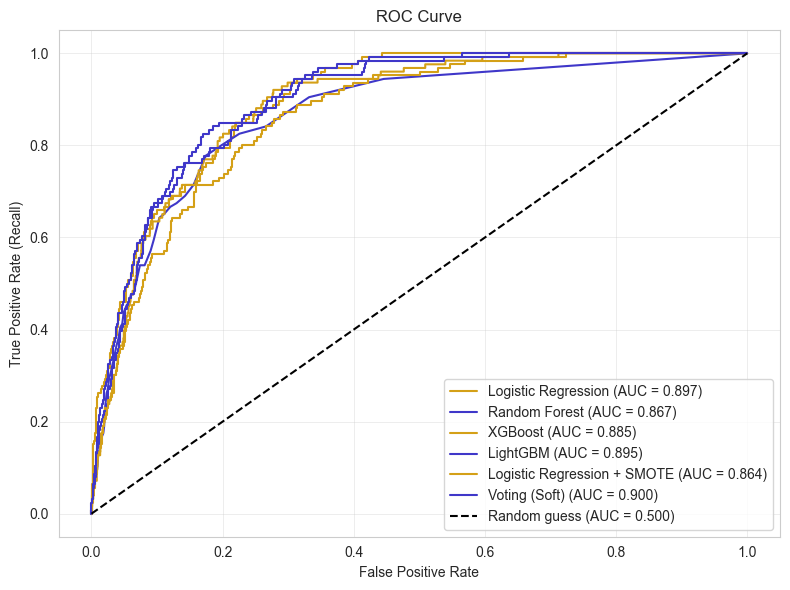

In [71]:
fig, ax = plt.subplots(figsize=(8, 6))

for name, model in fitted_models.items():
    y_proba = model.predict_proba(X_val)[:, 1]
    fpr, tpr, _ = roc_curve(y_val, y_proba)
    auc = roc_auc_score(y_val, y_proba)
    ax.plot(fpr, tpr, label=f'{name} (AUC = {auc:.3f})')

ax.plot([0, 1], [0, 1], 'k--', label='Random guess (AUC = 0.500)')
ax.set_xlabel('False Positive Rate')
ax.set_ylabel('True Positive Rate (Recall)')
ax.set_title('ROC Curve')
ax.legend(loc='lower right')
plt.tight_layout()
plt.show()

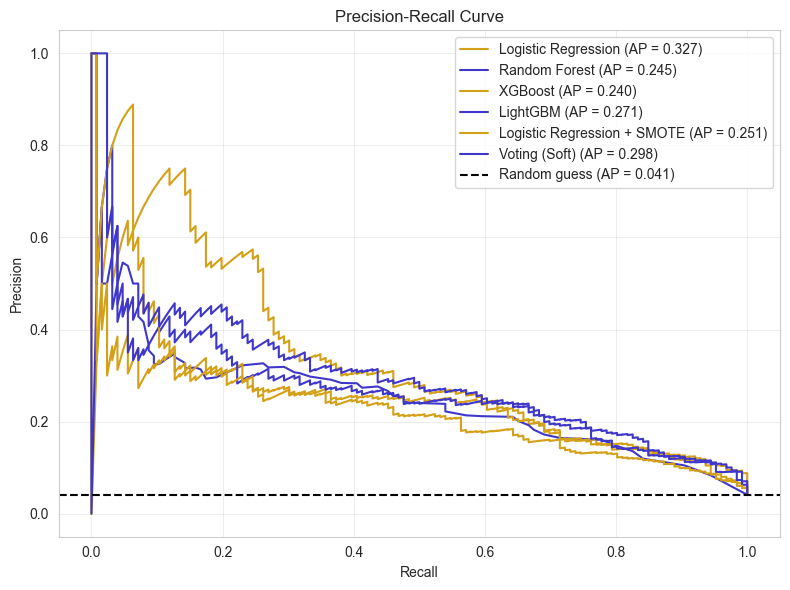

In [72]:
fig, ax = plt.subplots(figsize=(8, 6))

for name, model in fitted_models.items():
    y_proba = model.predict_proba(X_val)[:, 1]
    precision, recall, _ = precision_recall_curve(y_val, y_proba)
    ap = average_precision_score(y_val, y_proba)
    ax.plot(recall, precision, label=f'{name} (AP = {ap:.3f})')

baseline = y_val.mean()
ax.axhline(baseline, color='k', linestyle='--', label=f'Random guess (AP = {baseline:.3f})')
ax.set_xlabel('Recall')
ax.set_ylabel('Precision')
ax.set_title('Precision-Recall Curve')
ax.legend(loc='upper right')
plt.tight_layout()
plt.show()

#### Retrain and Save Model

In [73]:
X_train = train_inputs[numerical_cols + encoded_cols]
y_train = train_df[target_col]

In [74]:
preds = lr_with_smote.predict(X_test)
preds

array([0, 0, 0, ..., 0, 0, 0])

In [75]:
sub_df = preds

In [76]:
pd.DataFrame(sub_df).to_csv("submission.csv", index=None)

In [77]:
sub_df = pd.read_csv("submission.csv")
sub_df.head()

,0
0,0
1,0
2,0
3,1
4,0


### Make prediction on a single input

In [78]:
sub_df['stroke'] = preds

In [79]:
sub_df

,0,stroke
0,0,0
1,0,0
2,0,0
3,1,1
4,0,0
...,...,...
10198,0,0
10199,0,0
10200,0,0
10201,0,0


In [80]:
train_df.columns

Index(['id', 'gender', 'age', 'hypertension', 'heart_disease', 'ever_married',
       'work_type', 'Residence_type', 'avg_glucose_level', 'bmi',
       'smoking_status', 'stroke'],
      dtype='object')

In [81]:
train_df['smoking_status'].value_counts()

smoking_status
never smoked       6281
Unknown            4542
formerly smoked    2337
smokes             2143
Name: count, dtype: int64

In [82]:
single_input = {
    'gender': "Male",
    'age': 33,
    'hypertension': 0,
    'heart_disease': 0,
    'ever_married': "Yes",
    'work_type': "Private",
    'Residence_type': "Urban",
    'avg_glucose_level': 79.53,
    'bmi': 31.10,
    'smoking_status': 'formerly smoked'
}

In [83]:
input_df = pd.DataFrame([single_input])

In [84]:
input_df[encoded_cols] = preprocessor.transform(input_df)

In [85]:
X = input_df[numerical_cols + encoded_cols]

In [86]:
lr_with_smote.predict(X)

array([0])

### Saving the model

In [87]:
import joblib

In [88]:
model = {
    'encoded_cols': encoded_cols,
    'numeric-cols': numerical_cols,
    'preprocessor': preprocessor,
    'model': lr_with_smote
}

In [89]:
joblib.dump(model, 'model.joblib')

['model.joblib']